# ADAML Workshop 4 - RNN and LSTM

## Project Description

In this workshop, we will study RNN and LSTM by predicting the trajectory of a two-wheel-drive robot such as Roomba.

### Robot

The robot is a two wheeled robot. Each wheen can spin either forwards, backwards, or stay still. The robot moves and turns by spinning the wheels.

### Data

Each sequence starts at $(0,0)$ facing the positive x-direction. 
Each timestep the input contains:
    - Left and right wheel commands
    - A flag if the motor is running or not
    - A reset flag  (this we don't use now)
Commands are held for `command_duration` timesteps (0.1 s).

### Models 

The models (MLP, RNN, LSTM) predict the robots 2D position $(x, y)$ at every timestep -> reconstruction of the trajectory only from the motor commands.


## Tasks

1. Make sure you understand the models and the data.
    - Visualize data if needed.
2. Study how the models behave with different `sequence_length`
    - If you have time, you can doo random seed study as well
3. How does the LSTM memory affect the trajectory reconstruction?
4. Generalization:
    - Train the model with gentle turn and then test with sharper turns

**Each group should prepare a couple of plots to show others**


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

n_train = 4000
n_val = 1000
n_test = 1000

epochs = 80
batch_size = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [2]:
datasets = {}
trajectories = {}

sequence_lengths = [100,]

wheel_base = 0.095       # metres
max_wheel_speed = 0.15   # metres per second
dt = 0.1                # seconds per step
command_duration = 20   # steps per command

for sequence_length in sequence_lengths:
    rng = np.random.default_rng(42)
    n_samples = n_train + n_val + n_test

    n_commands = (
        sequence_length + command_duration - 1
    ) // command_duration

    # How much can the robot turn and go forward
    forward_command = rng.uniform(
        0.3, 0.9, size=(n_samples, n_commands)
    )
    turn_command = rng.uniform(
        -0.2, 0.2, size=(n_samples, n_commands)
    )

    wheel_commands = np.stack(
        [
            forward_command - turn_command,
            forward_command + turn_command,
        ],
        axis=-1,
    )
    wheel_commands = np.clip(wheel_commands, -1, 1)

    active = rng.random((n_samples, n_commands)) < 0.8

    wheel_commands = np.repeat(
        wheel_commands, command_duration, axis=1
    )[:, :sequence_length]

    active = np.repeat(
        active, command_duration, axis=1
    )[:, :sequence_length]

    reset = np.zeros((n_samples, sequence_length), dtype=bool)

    X = np.concatenate(
        [
            wheel_commands,
            active[..., None],
            reset[..., None],
        ],
        axis=-1,
    )

    pose = np.zeros((n_samples, sequence_length + 1, 3))

    for t in range(sequence_length):
        left_velocity = (
            max_wheel_speed * wheel_commands[:, t, 0] * active[:, t]
        )
        right_velocity = (
            max_wheel_speed * wheel_commands[:, t, 1] * active[:, t]
        )

        velocity = (left_velocity + right_velocity) / 2
        angular_velocity = (
            right_velocity - left_velocity
        ) / wheel_base

        angle_change = angular_velocity * dt
        midpoint_angle = pose[:, t, 2] + angle_change / 2

        distance = (
            velocity * dt * np.sinc(angle_change / (2 * np.pi))
        )

        pose[:, t + 1, 0] = (
            pose[:, t, 0] + distance * np.cos(midpoint_angle)
        )
        pose[:, t + 1, 1] = (
            pose[:, t, 1] + distance * np.sin(midpoint_angle)
        )
        pose[:, t + 1, 2] = pose[:, t, 2] + angle_change

    datasets[sequence_length] = (
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(pose[:, 1:, :2], dtype=torch.float32),
    )

    trajectories[sequence_length] = pose

for sequence_length in sequence_lengths:
    X, y = datasets[sequence_length]
    print(
        f"{sequence_length * dt:.0f} seconds: "
        f"inputs {tuple(X.shape)}, targets {tuple(y.shape)}"
    )

10 seconds: inputs (6000, 100, 4), targets (6000, 100, 2)


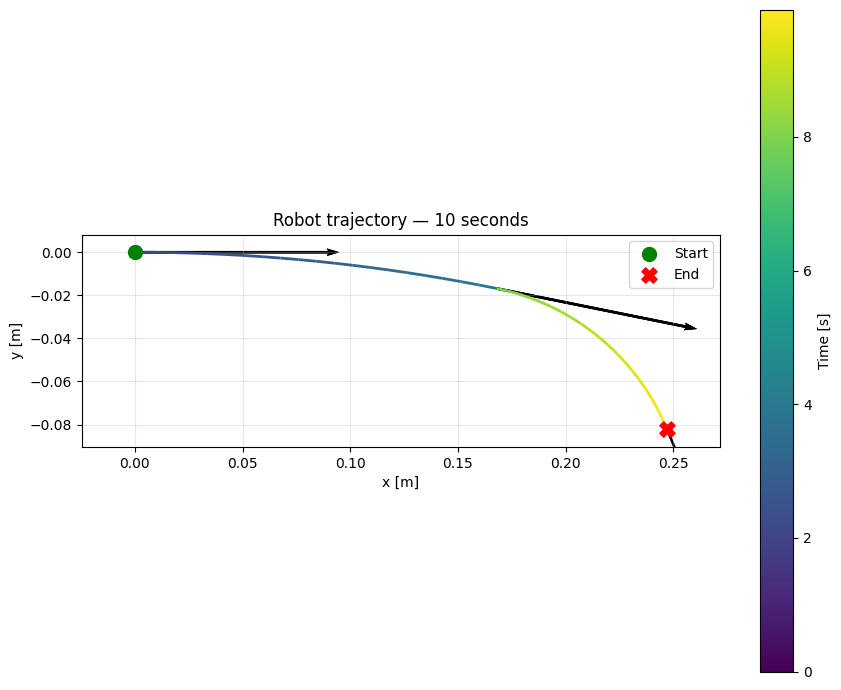

In [3]:
from matplotlib.collections import LineCollection

sequence_length = max(sequence_lengths)
sample_index = 0

pose = trajectories[sequence_length][sample_index]
position = pose[:, :2]

segments = np.stack([position[:-1], position[1:]], axis=1)
time_step = np.arange(sequence_length) * dt

fig, ax = plt.subplots(figsize=(9, 7))

trajectory = LineCollection(
    segments,
    cmap="viridis",
    linewidths=2,
)
trajectory.set_array(time_step)
ax.add_collection(trajectory)

arrow_steps = np.arange(0, len(pose), 20)

ax.quiver(
    pose[arrow_steps, 0],
    pose[arrow_steps, 1],
    np.cos(pose[arrow_steps, 2]),
    np.sin(pose[arrow_steps, 2]),
    angles="xy",
    scale_units="xy",
    scale=1 / wheel_base,
    color="black",
    width=0.004,
)

ax.scatter(
    position[0, 0], position[0, 1],
    color="green", s=100, label="Start", zorder=3,
)
ax.scatter(
    position[-1, 0], position[-1, 1],
    color="red", marker="X", s=120, label="End", zorder=3,
)

ax.autoscale_view()
ax.margins(0.1)
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title(f"Robot trajectory — {sequence_length * dt:.0f} seconds")
ax.grid(alpha=0.3)
ax.legend()

fig.colorbar(trajectory, ax=ax, label="Time [s]")

plt.tight_layout()
plt.show()

In [4]:
class MLP(nn.Module):
    def __init__(self, sequence_length):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(4 * sequence_length, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
        )

    def forward(self, X):
        return self.layers(X.flatten(start_dim=1))


class RNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=4,
            hidden_size=32,
            batch_first=True,
        )
        self.output = nn.Linear(32, 2)

    def forward(self, X):
        H, _ = self.rnn(X)
        return self.output(H[:, -1])


class LSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=4,
            hidden_size=32,
            batch_first=True,
        )
        self.output = nn.Linear(32, 2)

        with torch.no_grad():
            self.lstm.bias_ih_l0[32:64] = 3.0
            self.lstm.bias_hh_l0[32:64] = 0.0

    def forward(self, X):
        H, _ = self.lstm(X)
        return self.output(H[:, -1])

In [5]:
results = {
    name: [] for name in ["Mean baseline", "MLP", "RNN", "LSTM"]
}
validation_curves = {}
test_predictions = {}

for sequence_length in sequence_lengths:
    X, y = datasets[sequence_length]

    X_train = X[:n_train]
    y_train = y[:n_train]

    X_val = X[n_train:n_train + n_val].to(device)
    y_val = y[n_train:n_train + n_val].to(device)

    X_test = X[n_train + n_val:].to(device)
    y_test = y[n_train + n_val:]

    mean_position = y_train.mean(dim=0)

    baseline_rmse = torch.sqrt(
        ((y_test - mean_position) ** 2).mean()
    ).item()

    results["Mean baseline"].append(baseline_rmse)

    for model_name in ["MLP", "RNN", "LSTM"]:
        torch.manual_seed(42)

        if model_name == "MLP":
            model = MLP(sequence_length)
        elif model_name == "RNN":
            model = RNN()
        else:
            model = LSTM()

        model = model.to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

        train_loader = DataLoader(
            TensorDataset(X_train, y_train),
            batch_size=batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(42),
        )

        validation_losses = []

        print(f"\n{model_name}, sequence length = {sequence_length}")
        print("Parameters:", sum(p.numel() for p in model.parameters()))

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        for epoch in range(epochs):
            model.train()

            for X_batch, y_batch in train_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                optimizer.zero_grad()

                prediction = model(X_batch)
                loss = ((prediction - y_batch) ** 2).mean()

                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            model.eval()

            with torch.no_grad():
                prediction = model(X_val)
                val_rmse = torch.sqrt(
                    ((prediction - y_val) ** 2).mean()
                ).item()

            validation_losses.append(val_rmse)

            if (epoch + 1) % 20 == 0:
                print(
                    f"Epoch {epoch + 1}: "
                    f"validation RMSE = {val_rmse:.4f}"
                )

        if device.type == "cuda":
            torch.cuda.synchronize()

        training_time = time.perf_counter() - start_time

        with torch.no_grad():
            prediction = model(X_test).cpu()

        test_rmse = torch.sqrt(
            ((prediction - y_test) ** 2).mean()
        ).item()

        results[model_name].append(test_rmse)
        validation_curves[(model_name, sequence_length)] = validation_losses
        test_predictions[(model_name, sequence_length)] = prediction

        print(f"Test RMSE: {test_rmse:.4f}")
        print(f"Training time: {training_time:.1f} s")


MLP, sequence length = 100
Parameters: 25794


RuntimeError: The size of tensor a (128) must match the size of tensor b (100) at non-singleton dimension 1

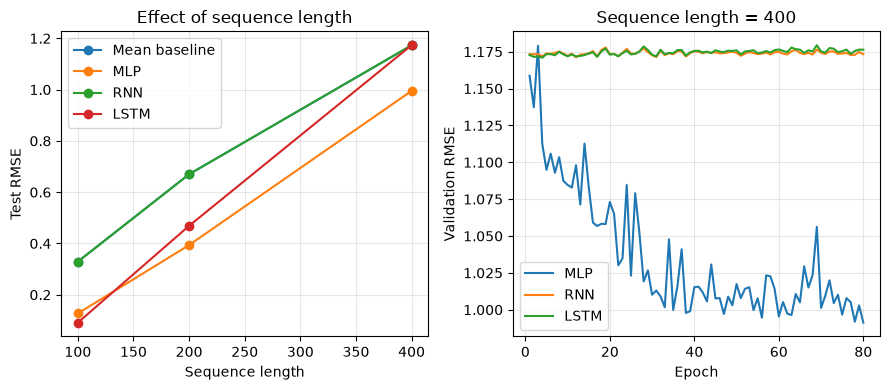

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for model_name, errors in results.items():
    axes[0].plot(
        sequence_lengths, errors, marker="o", label=model_name
    )

longest_sequence = max(sequence_lengths)

for model_name in ["MLP", "RNN", "LSTM"]:
    axes[1].plot(
        np.arange(1, epochs + 1),
        validation_curves[(model_name, longest_sequence)],
        label=model_name,
    )

axes[0].set_xlabel("Sequence length")
axes[0].set_ylabel("Test RMSE")
axes[0].set_title("Effect of sequence length")

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation RMSE")
axes[1].set_title(f"Sequence length = {longest_sequence}")

for axis in axes:
    axis.legend()
    axis.grid(alpha=0.3)

plt.tight_layout()
plt.show()

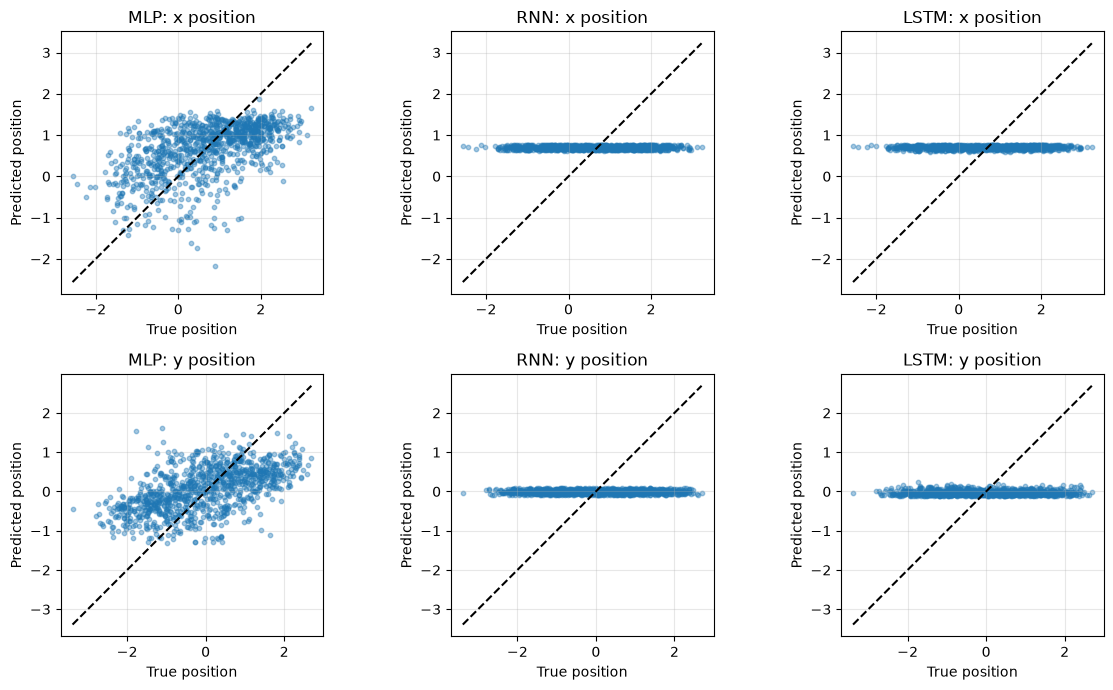

In [42]:
_, y = datasets[longest_sequence]
y_test = y[n_train + n_val:]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for column, model_name in enumerate(["MLP", "RNN", "LSTM"]):
    prediction = test_predictions[(model_name, longest_sequence)]

    for coordinate, coordinate_name in enumerate(["x", "y"]):
        axis = axes[coordinate, column]

        true_values = y_test[:, coordinate].numpy()
        predicted_values = prediction[:, coordinate].numpy()

        lower = min(true_values.min(), predicted_values.min())
        upper = max(true_values.max(), predicted_values.max())

        axis.scatter(
            true_values,
            predicted_values,
            s=10,
            alpha=0.4,
        )
        axis.plot([lower, upper], [lower, upper], "k--")

        axis.set_title(f"{model_name}: {coordinate_name} position")
        axis.set_xlabel("True position")
        axis.set_ylabel("Predicted position")
        axis.set_aspect("equal", adjustable="box")
        axis.grid(alpha=0.3)

plt.tight_layout()
plt.show()